In [ ]:
import pandas as pd

In [ ]:
import numpy as np

In [ ]:
import matplotlib.pyplot as plt

In [ ]:
import seaborn as sns

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [ ]:
df = pd.read_csv("ai_jobs_salaries_clean.csv")

In [ ]:
print(df.shape)

(71913, 17)


In [ ]:
print(df.info())

In [ ]:
print(df.head())

   work_year experience_level employment_type       job_title  salary  \
0       2025               EX              FT    Head of Data  348516   
1       2025               EX              FT    Head of Data  232344   
2       2025               SE              FT  Data Scientist  145400   
3       2025               SE              FT  Data Scientist   81600   
4       2025               MI              FT        Engineer  160000   

  salary_currency  salary_in_usd employee_residence  remote_ratio  \
0             USD         348516                 US             0   
1             USD         232344                 US             0   
2             USD         145400                 US             0   
3             USD          81600                 US             0   
4             USD         160000                 US           100   

  company_location company_size experience_level_label employment_type_label  \
0               US            M        Executive-level            

In [ ]:
print(df.describe())

print(df.describe(include="object"))

          work_year        salary  salary_in_usd  remote_ratio
count  71913.000000  7.191300e+04   71913.000000  71913.000000
mean    2024.425153  1.617102e+05  151161.252625     24.569271
std        0.721198  2.872868e+05   77329.594122     42.917779
min     2020.000000  1.400000e+04   15000.000000      0.000000
25%     2024.000000  9.640000e+04   96000.000000      0.000000
50%     2025.000000  1.397000e+05  138750.000000      0.000000
75%     2025.000000  1.922000e+05  190315.000000      0.000000
max     2025.000000  3.040000e+07  800000.000000    100.000000
       experience_level employment_type       job_title salary_currency  \
count             71913           71913           71913           71913   
unique                4               4             422              26   
top                  SE              FT  Data Scientist             USD   
freq              37702           71163            7160           65910   

       employee_residence company_location company_size  

In [ ]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [ ]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
work_year                     0
experience_level              0
employment_type               0
job_title                     0
salary                        0
salary_currency               0
salary_in_usd                 0
employee_residence            0
remote_ratio                  0
company_location              0
company_size                  0
experience_level_label        0
employment_type_label         0
work_mode                     0
salary_outlier_flag           0
role_family                   0
isco_group_hint           40540
dtype: int64


isco_group_hint    40540
dtype: int64


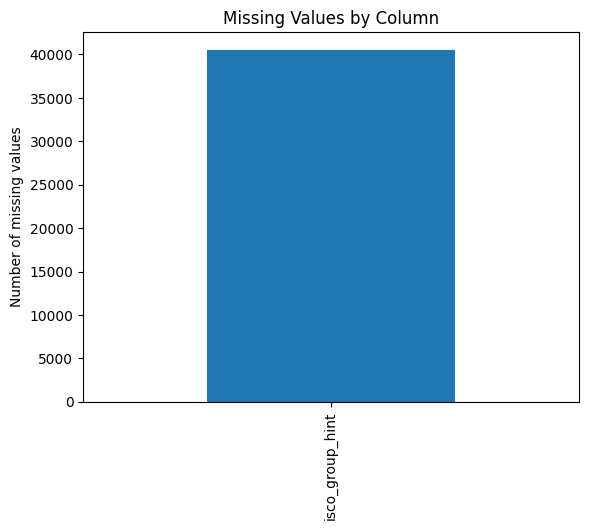

In [ ]:
missing = df.isnull().sum()

print(missing[missing > 0])


missing[missing > 0].sort_values().plot(
    kind="bar",
    title="Missing Values by Column"
)

plt.ylabel("Number of missing values")
plt.show()

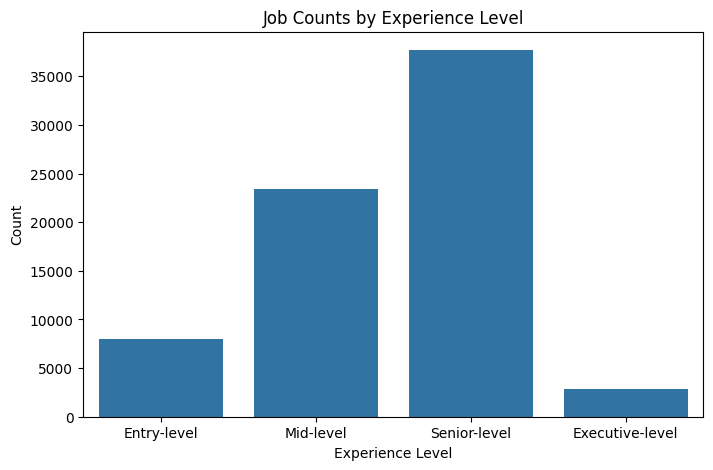

In [ ]:
order = ["Entry-level", "Mid-level", "Senior-level", "Executive-level"]

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="experience_level_label", order=order)
plt.title("Job Counts by Experience Level")
plt.xlabel("Experience Level")
plt.ylabel("Count")
plt.show()

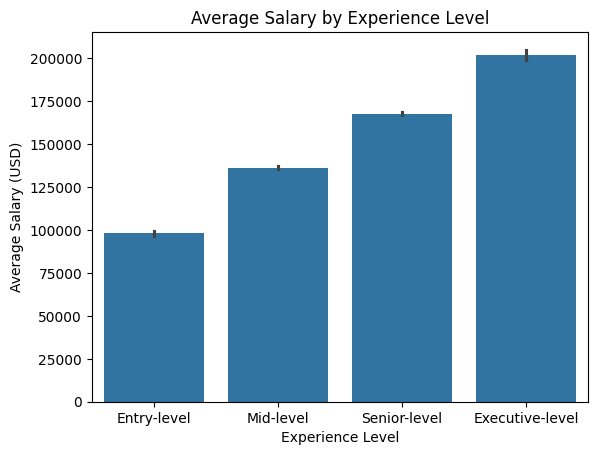

In [ ]:
sns.barplot(
    data=df,
    x="experience_level_label",
    y="salary_in_usd",
    order=order
)

plt.title("Average Salary by Experience Level")
plt.xlabel("Experience Level")
plt.ylabel("Average Salary (USD)")
plt.show()

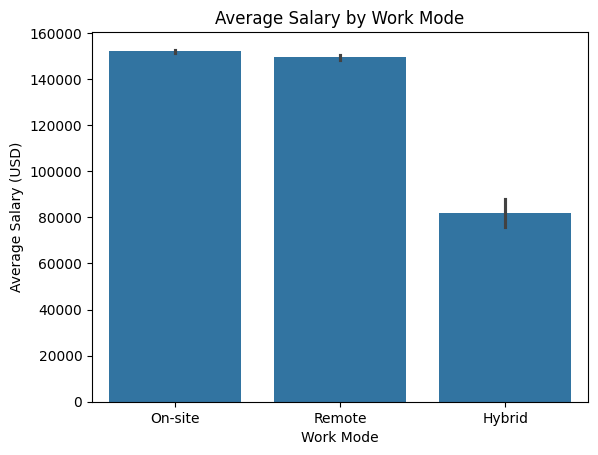

In [ ]:
sns.barplot(
    data=df,
    x="work_mode",
    y="salary_in_usd"
)

plt.title("Average Salary by Work Mode")
plt.xlabel("Work Mode")
plt.ylabel("Average Salary (USD)")
plt.show()


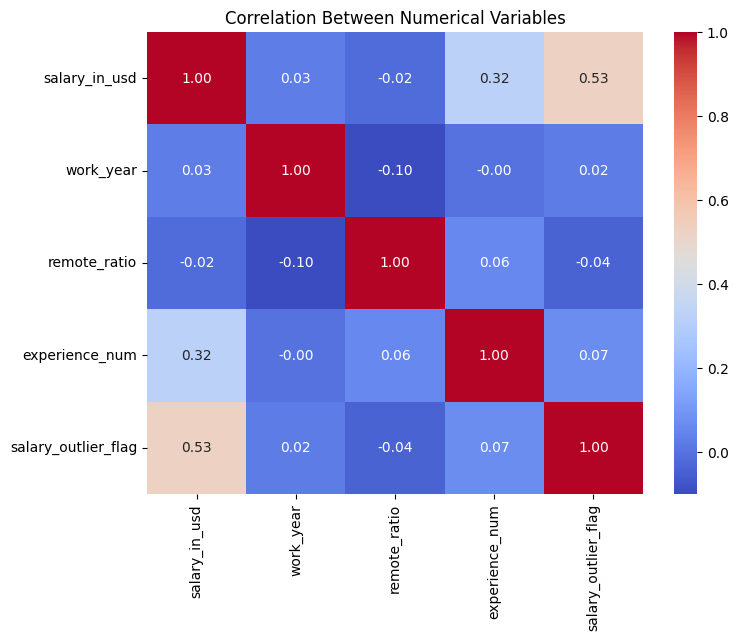

In [ ]:
level_map = {"EN": 1, "MI": 2, "SE": 3, "EX": 4}
df["experience_num"] = df["experience_level"].map(level_map)

df["salary_outlier_flag"] = df["salary_outlier_flag"].astype(int)

cols = ["salary_in_usd", "work_year", "remote_ratio",
        "experience_num", "salary_outlier_flag"]

plt.figure(figsize=(8, 6))
sns.heatmap(
    df[cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Numerical Variables")
plt.show()

In [ ]:
df = df.drop_duplicates()

print("Dataset shape:", df.shape)

Dataset shape: (71913, 18)


In [ ]:
df["IscoKnown"] = df["isco_group_hint"].notna().astype(int)

df = df.drop(columns=["isco_group_hint"])

In [ ]:
level_map = {"EN": 1, "MI": 2, "SE": 3, "EX": 4}
df["ExperienceNum"] = df["experience_level"].map(level_map)

df["IsRemote"] = (df["remote_ratio"] == 100).astype(int)

df["WorksAbroad"] = (df["employee_residence"] != df["company_location"]).astype(int)
df["IsSenior"] = df["experience_level"].isin(["SE", "EX"]).astype(int)

print(
    df[["experience_level", "ExperienceNum", "remote_ratio", "IsRemote",
        "WorksAbroad", "IsSenior"]].head()
)

  experience_level  ExperienceNum  remote_ratio  IsRemote  WorksAbroad  \
0               EX              4             0         0            0   
1               EX              4             0         0            0   
2               SE              3             0         0            0   
3               SE              3             0         0            0   
4               MI              2           100         1            0   

   IsSenior  
0         1  
1         1  
2         1  
3         1  
4         0  


In [ ]:
level_map = {"EN": 1, "MI": 2, "SE": 3, "EX": 4}
df["ExperienceNum"] = df["experience_level"].map(level_map)
df["IsRemote"] = (df["remote_ratio"] == 100).astype(int)
df["WorksAbroad"] = (df["employee_residence"] != df["company_location"]).astype(int)
df["IsSenior"] = df["experience_level"].isin(["SE", "EX"]).astype(int)

# ---- Target ----
df["HighSalary"] = (df["salary_in_usd"] > df["salary_in_usd"].median()).astype(int)

# ---- Features and target ----
X = df[
    ["ExperienceNum", "company_size", "work_year", "employment_type",
     "role_family", "IsRemote", "WorksAbroad", "IsSenior"]
]
y = df["HighSalary"]

print("Features:")
print(X.head())
print("Target:")
print(y.head())

Features:
   ExperienceNum company_size  work_year employment_type  \
0              4            M       2025              FT   
1              4            M       2025              FT   
2              3            M       2025              FT   
3              3            M       2025              FT   
4              2            M       2025              FT   

            role_family  IsRemote  WorksAbroad  IsSenior  
0     Analytics Manager         0            0         1  
1     Analytics Manager         0            0         1  
2        Data Scientist         0            0         1  
3        Data Scientist         0            0         1  
4  Other / Unclassified         1            0         0  
Target:
0    1
1    1
2    1
3    0
4    1
Name: HighSalary, dtype: int64


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

print("Training class proportions:")
print(y_train.value_counts(normalize=True))

print("Testing class proportions:")
print(y_test.value_counts(normalize=True))

Training rows: 57530
Testing rows: 14383
Training class proportions:
HighSalary
0    0.50007
1    0.49993
Name: proportion, dtype: float64
Testing class proportions:
HighSalary
0    0.500104
1    0.499896
Name: proportion, dtype: float64


In [ ]:
numeric_features = [
    "ExperienceNum", "work_year",
    "IsRemote", "WorksAbroad", "IsSenior"
]

categorical_features = [
    "company_size", "employment_type", "role_family"
]

In [ ]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [ ]:
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore",
                              sparse_output=False))
])


In [ ]:
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

In [ ]:
X_train_prepared = preprocessor.fit_transform(X_train)

X_test_prepared = preprocessor.transform(X_test)

print("Training shape:", X_train_prepared.shape)
print("Testing shape:", X_test_prepared.shape)

Training shape: (57530, 23)
Testing shape: (14383, 23)


In [ ]:
print("Missing values in training:",
      np.isnan(X_train_prepared).sum())

print("Missing values in testing:",
      np.isnan(X_test_prepared).sum())

print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Missing values in training: 0
Missing values in testing: 0
Training target shape: (57530,)
Testing target shape: (14383,)


In [12]:
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

import matplotlib.pyplot as plt
import pandas as pd

In [13]:
df = pd.read_csv("ai_jobs_salaries_clean.csv")

# 2. Target: 1 = salary above median, 0 = at or below
df["high_salary"] = (df["salary_in_usd"] > df["salary_in_usd"].median()).astype(int)

# 3. Features
numeric_cols = ["work_year", "remote_ratio"]
categorical_cols = ["experience_level", "employment_type", "employee_residence",
                    "company_location", "company_size", "role_family"]
X = df[numeric_cols + categorical_cols]
y = df["high_salary"]

# 4. Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 5. Preprocess
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
])
X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)

print("Ready:", X_train_prepared.shape, X_test_prepared.shape)

Ready: (57530, 218) (14383, 218)


In [14]:
# Train Logistic Regression
logistic_model = LogisticRegression(max_iter=1000)
logistic_model.fit(X_train_prepared, y_train)

logistic_predictions = logistic_model.predict(X_test_prepared)

print("First 10 predictions:", logistic_predictions[:10])
print("First 10 actual values:", y_test.iloc[:10].tolist())
print("Accuracy:", round(accuracy_score(y_test, logistic_predictions), 3))
print(classification_report(y_test, logistic_predictions))

First 10 predictions: [0 0 1 0 1 0 1 1 0 0]
First 10 actual values: [0, 1, 0, 0, 1, 1, 1, 0, 0, 0]
Accuracy: 0.684
              precision    recall  f1-score   support

           0       0.68      0.70      0.69      7193
           1       0.69      0.67      0.68      7190

    accuracy                           0.68     14383
   macro avg       0.68      0.68      0.68     14383
weighted avg       0.68      0.68      0.68     14383



In [15]:
#Train KNN

knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train_prepared, y_train)

knn_predictions = knn_model.predict(X_test_prepared)

print("First 10 KNN predictions:", knn_predictions[:10])


First 10 KNN predictions: [0 1 1 0 0 0 1 1 0 0]


In [16]:

tree_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

tree_model.fit(X_train_prepared, y_train)

tree_predictions = tree_model.predict(X_test_prepared)

print("First 10 tree predictions:", tree_predictions[:10])


First 10 tree predictions: [0 0 1 0 1 0 1 1 0 0]


In [19]:
#Evaluate all three classifiers
def evaluate_model(name, y_true, y_pred):
    labels = ["Lower salary", "High salary"]

    print("\nModel:", name)
    print("Accuracy:", accuracy_score(y_true, y_pred))
    print("F1-score:", f1_score(y_true, y_pred, zero_division=0))

    print("\nClassification report:")
    print(classification_report(
        y_true,
        y_pred,
        target_names=labels,
        zero_division=0
    ))

    cm = confusion_matrix(y_true, y_pred)
    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=labels
    )
    display.plot()
    plt.title(name + " Confusion Matrix")
    plt.show()




Model: Logistic Regression
Accuracy: 0.6837933671695752
F1-score: 0.6790402258292166

Classification report:
              precision    recall  f1-score   support

Lower salary       0.68      0.70      0.69      7193
 High salary       0.69      0.67      0.68      7190

    accuracy                           0.68     14383
   macro avg       0.68      0.68      0.68     14383
weighted avg       0.68      0.68      0.68     14383



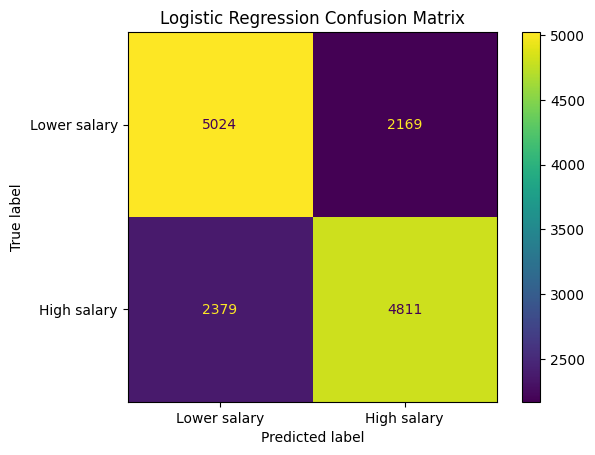


Model: KNN
Accuracy: 0.5875686574428144
F1-score: 0.5145662847790508

Classification report:
              precision    recall  f1-score   support

Lower salary       0.57      0.74      0.64      7193
 High salary       0.63      0.44      0.51      7190

    accuracy                           0.59     14383
   macro avg       0.60      0.59      0.58     14383
weighted avg       0.60      0.59      0.58     14383



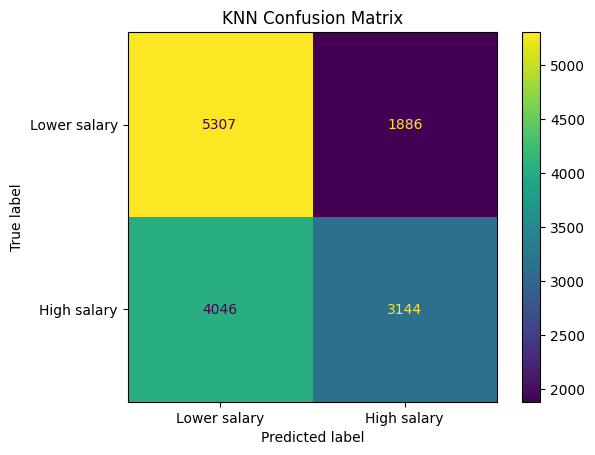


Model: Decision Tree
Accuracy: 0.680456093999861
F1-score: 0.6734867860187553

Classification report:
              precision    recall  f1-score   support

Lower salary       0.67      0.70      0.69      7193
 High salary       0.69      0.66      0.67      7190

    accuracy                           0.68     14383
   macro avg       0.68      0.68      0.68     14383
weighted avg       0.68      0.68      0.68     14383



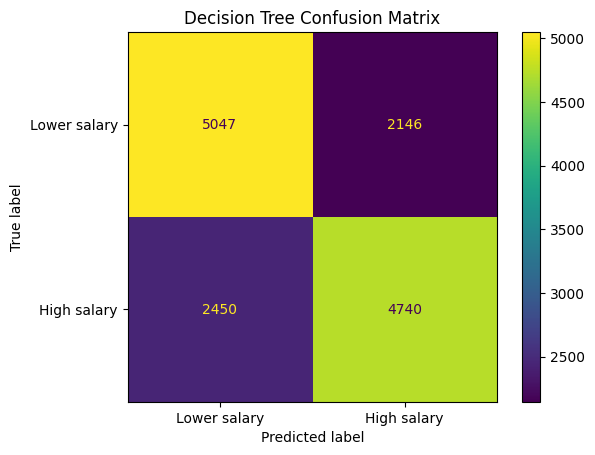

In [20]:
#calling the method (function)
evaluate_model("Logistic Regression",
               y_test, logistic_predictions)

evaluate_model("KNN",
               y_test, knn_predictions)

evaluate_model("Decision Tree",
               y_test, tree_predictions)

In [21]:
#One important difference: Linear Regression predicts a numerical value, whereas passenger
#survival is a classification problem. To demonstrate Linear Regression appropriately,
#we can use it to predict ticket fare from other passenger information.

In [23]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import mean_absolute_error, r2_score

# Features used to predict salary
salary_num_features = ["work_year", "remote_ratio"]
salary_cat_features = ["experience_level", "employment_type", "employee_residence",
                       "company_location", "company_size", "role_family"]
salary_features = salary_num_features + salary_cat_features

X_salary_train = X_train[salary_features]
X_salary_test = X_test[salary_features]

# Target: actual salary in USD (looked up from df using the same rows)
y_salary_train = df.loc[X_train.index, "salary_in_usd"]
y_salary_test = df.loc[X_test.index, "salary_in_usd"]

salary_preprocessor = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), salary_num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), salary_cat_features),
])

salary_model = make_pipeline(
    salary_preprocessor,
    LinearRegression()
)

salary_model.fit(X_salary_train, y_salary_train)

salary_predictions = salary_model.predict(X_salary_test)

print("Actual salaries:", y_salary_test.head().tolist())
print("Predicted salaries:", salary_predictions[:5].round(0))

print("Mean Absolute Error:",
      mean_absolute_error(y_salary_test, salary_predictions))
print("R2 score:", r2_score(y_salary_test, salary_predictions))

Actual salaries: [72900, 162600, 104500, 77791, 250000]
Predicted salaries: [141802. 144483. 170980.  88167. 175607.]
Mean Absolute Error: 49773.33532463461
R2 score: 0.21904656503277686


In [24]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "KNN",
        "Decision Tree"
    ],
    "Accuracy": [
        accuracy_score(y_test, logistic_predictions),
        accuracy_score(y_test, knn_predictions),
        accuracy_score(y_test, tree_predictions)
    ],
    "F1-score": [
        f1_score(y_test, logistic_predictions),
        f1_score(y_test, knn_predictions),
        f1_score(y_test, tree_predictions)
    ]
})

print(results.round(3))

                 Model  Accuracy  F1-score
0  Logistic Regression     0.684     0.679
1                  KNN     0.588     0.515
2        Decision Tree     0.680     0.673


In [25]:
#Week 4

In [26]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import HistGradientBoostingClassifier

from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_score,
    GridSearchCV
)

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)


In [27]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier


In [28]:
X_train_dense = X_train_prepared.toarray()
X_test_dense = X_test_prepared.toarray()

# Baseline: Decision Tree
baseline_tree = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)
baseline_tree.fit(X_train_dense, y_train)

# Ensemble 1: Random Forest
random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
random_forest.fit(X_train_dense, y_train)

# Ensemble 2: Boosting
boosting_model = HistGradientBoostingClassifier(
    max_iter=100,
    learning_rate=0.1,
    random_state=42
)
boosting_model.fit(X_train_dense, y_train)

print("All three models have been trained.")

All three models have been trained.


In [30]:
models = {
    "Decision Tree": baseline_tree,
    "Random Forest": random_forest,
    "Boosting": boosting_model
}

results = []

for name, model in models.items():
    predictions = model.predict(X_test_dense)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "F1-score": f1_score(y_test, predictions)
    })

results_df = pd.DataFrame(results)

print(results_df.round(3))

           Model  Accuracy  F1-score
0  Decision Tree     0.680     0.673
1  Random Forest     0.682     0.687
2       Boosting     0.687     0.685


In [31]:
#Cross-validation

In [32]:
from sklearn.model_selection import StratifiedKFold, cross_val_score


In [34]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for name, model in models.items():
    scores = cross_val_score(
        model,
        X_train_dense,
        y_train,
        cv=cv,
        scoring="f1"
    )

    print(name)
    print("Fold scores:", scores.round(3))
    print("Mean F1-score:", round(scores.mean(), 3))

Decision Tree
Fold scores: [0.675 0.67  0.671 0.67  0.65 ]
Mean F1-score: 0.667
Random Forest
Fold scores: [0.696 0.686 0.685 0.691 0.673]
Mean F1-score: 0.686
Boosting
Fold scores: [0.694 0.683 0.681 0.687 0.671]
Mean F1-score: 0.683


In [36]:
#Hyperparameter tuning
#Tune KNN

In [37]:
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier


In [43]:
knn_grid = GridSearchCV(
    estimator=KNeighborsClassifier(),
    param_grid={
        "n_neighbors": [5, 9, 15]
    },
    cv=3,
    scoring="f1",
    return_train_score=False,
    n_jobs=-1
)

knn_grid.fit(X_train_dense, y_train)

print("Best K:", knn_grid.best_params_)
print("Best CV F1-score:", round(knn_grid.best_score_, 3))

best_knn = knn_grid.best_estimator_

Best K: {'n_neighbors': 15}
Best CV F1-score: 0.695


In [44]:
#Tune Decision Tree depth

In [45]:
tree_grid = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid={
        "max_depth": [2, 3, 4, 5, 7, 10, None]
    },
    cv=cv,
    scoring="f1",
    return_train_score=True,
    n_jobs=-1
)

tree_grid.fit(X_train_prepared, y_train)

print("Best tree settings:", tree_grid.best_params_)
print("Best CV F1-score:", round(tree_grid.best_score_, 3))

best_tree = tree_grid.best_estimator_


Best tree settings: {'max_depth': 2}
Best CV F1-score: 0.69


In [46]:
#Demonstrate overfitting using tree depth
#Let's compare training and cross-validation F1-scores from the Decision Tree grid search.

In [47]:
tree_results = pd.DataFrame(tree_grid.cv_results_)

print(
    tree_results[
        [
            "param_max_depth",
            "mean_train_score",
            "mean_test_score"
        ]
    ].round(3)
)

  param_max_depth  mean_train_score  mean_test_score
0               2             0.693            0.690
1               3             0.657            0.657
2               4             0.663            0.661
3               5             0.669            0.667
4               7             0.682            0.679
5              10             0.686            0.681
6            None             0.696            0.685


In [48]:
#Visualize the results

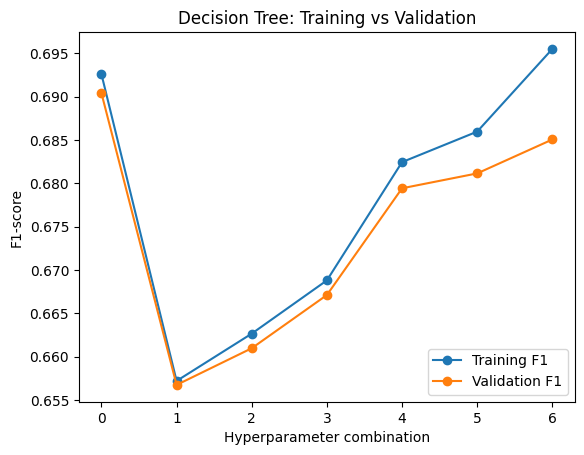

In [49]:
plt.plot(
    range(len(tree_results)),
    tree_results["mean_train_score"],
    marker="o",
    label="Training F1"
)

plt.plot(
    range(len(tree_results)),
    tree_results["mean_test_score"],
    marker="o",
    label="Validation F1"
)

plt.xlabel("Hyperparameter combination")
plt.ylabel("F1-score")
plt.title("Decision Tree: Training vs Validation")
plt.legend()
plt.show()


In [50]:
#Final evaluation on the untouched test set

In [52]:

final_models = {
    "Tuned KNN": best_knn,
    "Tuned Decision Tree": best_tree,
    "Random Forest": random_forest,
    "Boosting": boosting_model
}

final_results = []

for name, model in final_models.items():
    predictions = model.predict(X_test_prepared.toarray() if hasattr(X_test_prepared, "toarray") else X_test_prepared)

    final_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "F1-score": f1_score(y_test, predictions)
    })

final_df = pd.DataFrame(final_results)

print(final_df.round(3))


                 Model  Accuracy  F1-score
0            Tuned KNN     0.669     0.698
1  Tuned Decision Tree     0.637     0.710
2        Random Forest     0.682     0.687
3             Boosting     0.687     0.685


# New Section